intro_to_Language_modeling part3 - Initial optimizations
-----

[viedo link](https://youtu.be/P6sfmUTpUmc)

<u>**Goal**</u>

similar to earlier model you're training a neural network to predict the next character in a name based on a fixed-length context of previous characters

Additionally we do the following optimization(initial optimization to the neural network)
1. reducing initial (high) loss during training
2. fixing saturated tanh

<u>**Model Structure**</u>

1 input layer = 3-character context (as indices)

1 hidden layer = 1 layer with 200 neurons

1 output layer = prediction of the next character (as 1 of 27 logits)

<u>**Activation functions**</u>

Hidden layer : tahn - The hidden layer uses the tanh activation function to introduce non-linearity

Output layer : softmax(part of F.cross_entropy) - softmax is applied to logits to convert them into a probability distribution over the output characters


Computation Graph - Forward Pass


        Input indices (Xb)
          ↓
        [C] (Embedding matrix lookup)
          → emb: shape [batch_size, block_size, n_embd]
          ↓
        View: Flatten embedding vectors
          → embcat: shape [batch_size, block_size * n_embd]
          ↓
        Linear transformation: embcat @ W1 + b1
          → hpreact: hidden pre-activation (shape [batch_size, n_hidden])
          ↓
        tanh activation
          → h: hidden activation (same shape)
          ↓
        Linear transformation: h @ W2 + b2
          → logits: raw class scores (shape [batch_size, vocab_size])
          ↓
        Cross-entropy loss with Yb (target labels)
          → loss: scalar

Computation Graph - Back Pass

        loss
          ↑
        CrossEntropy(logits, Yb)
          ↑
        logits = h @ W2 + b2
          ↑              ↑
        grad_W2       grad_b2
          ↑
        h = tanh(hpreact)
          ↑
        hpreact = embcat @ W1 + b1
          ↑              ↑
        grad_W1       grad_b1
          ↑
        embcat = flatten(emb)
          ↑
        emb = C[Xb]      (C is updated based on which indices were used)
          ↑
        grad_C (only for used indices in batch)

Initial Setup
-----

In [19]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [20]:
# download the training data
!curl https://raw.githubusercontent.com/karpathy/makemore/refs/heads/master/names.txt -o names.txt

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  222k  100  222k    0     0   353k      0 --:--:-- --:--:-- --:--:--  353k


In [21]:
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [22]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [23]:
# build the dataset for training,dev and test split
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):
  X, Y = [], []

  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])     # 80% training split
Xdev, Ydev = build_dataset(words[n1:n2])   # 10% dev split
Xte,  Yte  = build_dataset(words[n2:])     # 10% test split

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


Previous Neuralnet Revised
-------

same logic as previous(i.e part2) but refactored for readablity and performance

In [24]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g)
b1 = torch.randn(n_hidden,                        generator=g)
W2 = torch.randn((n_hidden, vocab_size),          generator=g)
b2 = torch.randn(vocab_size,                      generator=g)

# parameters
parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

11897


In [25]:
# Training the neuralnel - same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

      0/ 200000: 27.8817
  10000/ 200000: 2.9692
  20000/ 200000: 2.5381
  30000/ 200000: 2.8408
  40000/ 200000: 2.0277
  50000/ 200000: 2.4590
  60000/ 200000: 2.4944
  70000/ 200000: 2.1338
  80000/ 200000: 2.4030
  90000/ 200000: 2.3502
 100000/ 200000: 2.0447
 110000/ 200000: 2.3922
 120000/ 200000: 1.9163
 130000/ 200000: 2.3493
 140000/ 200000: 2.2710
 150000/ 200000: 2.1671
 160000/ 200000: 2.0766
 170000/ 200000: 1.8112
 180000/ 200000: 2.0169
 190000/ 200000: 1.8818


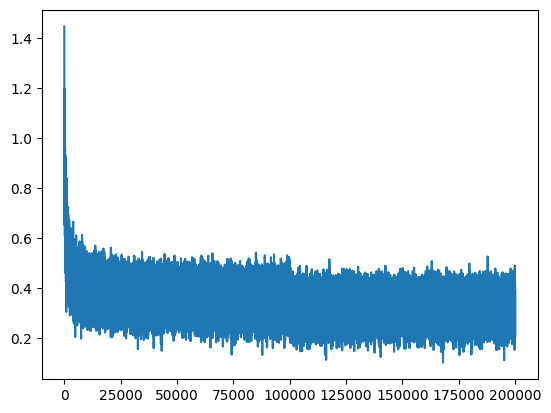

In [26]:
plt.plot(lossi)

In [27]:
# checking the train and val/dev loss
@torch.no_grad() # this decorator disables gradient tracking of pytorch
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  h = torch.tanh(embcat @ W1 + b1) # (N, n_hidden)
  logits = h @ W2 + b2 # (N, vocab_size)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.124457836151123
val 2.1642823219299316


In [28]:
# sampling from neuralnet
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20): # generating 20 samples

    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      # one sample index
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      # shift the contexxt window . eg '..e'
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0: # breaks the while loop on char '.'
        break

    print(''.join(itos[i] for i in out))

mora.
mayah.
seel.
nah.
yal.
ren.
ruchadrieg.
adelyn.
eliianni.
jen.
eden.
estanar.
kayzion.
kamin.
shubergshiriel.
kendreth.
konnie.
cayu.
zen.
dariyah.


Neuralnet optimization 01 - reducing initial loss
----------

We see that in previous section the initial loss during trainging was too high(i.e 27.8817)

**Why is initial loss too high?**

Model parameters (weights & biases) are randomly initialized and the first predictions are essentially random guesses. This leads to a high loss because the model's initial outputs are far from the correct target values.

**What is the expected as initial loss?**

Ideally, during the first training cycle, we would want our model to predict all 27 characters to have the same probability. This means we want the probabilities to be uniformly distributed among the 27 characters.

To achieve a uniformly distributed probability after the softmax activation, we would want all the logits (the raw outputs of the network before the softmax) to be roughly zero or the same value. This is because the softmax function, when applied to zero or equal logits, results in a uniform probability distribution.

The subsequent code cell implements the optimization of multiplying the W2 weights by 0.01 and setting the b2 biases to 0. This directly addresses the goal of making the initial logits closer to zero, thereby moving the initial predictions towards a more uniform distribution and reducing the initial loss

**Note:** The most effective way to make the initial logits close to zero and achieve a more uniform initial probability distribution is to directly adjust the parameters of the output layer (W2 and b2), which have a linear relationship with the logits

[link](https://youtu.be/P6sfmUTpUmc?list=PLAqhIrjkxbuWI23v9cThsA9GvCAUhRvKZ&t=302)

**why we use 0.01 and not 0 for W2 ?**

1. Breaking Symmetry: If we were to initialize all weights in W2 to zero, the gradients for all neurons in the hidden layer would be the same during the first backward pass. This is because the gradient of the loss with respect to the hidden layer output (h) depends on W2. If W2 is all zeros, this gradient will be the same for all hidden neurons, leading to them learning the same features. This is known as the "symmetry breaking" problem. By initializing W2 with small random values (achieved by multiplying torch.randn by 0.01), we break this symmetry and allow different hidden neurons to learn different aspects of the input data.

2. Allowing for Learning: While we want the initial logits to be close to zero for a uniform probability distribution, we don't want them to be exactly zero all the time. A small non-zero value in W2 allows for slight variations in the initial logits based on the hidden layer output (h). This provides a starting point for the network to learn and adjust the weights during training. If W2 were all zeros, the initial logits would always be zero (assuming b2 is also zero), and the network would have difficulty learning meaningful relationships between the hidden layer and the output.

3. Small Initial Gradients: Multiplying W2 by a small value ensures that the initial gradients with respect to the hidden layer (h) and the parameters of the first layer (W1 and b1) are also small. This helps in preventing large updates to the parameters during the initial steps of training, which can sometimes lead to instability.

In summary, scaling W2 by a small non-zero value like 0.01 helps in breaking symmetry, allows the network to start learning, and contributes to more stable training in the initial stages, while still achieving the goal of having initial logits close to zero for a more uniform initial probability distribution


In [29]:
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g)
b1 = torch.randn(n_hidden,                        generator=g)

### fixing the initial high loss ###
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.01 #here we multiply weights by 0.01. This is done to make the initial weights closer to zero, which helps in reducing the initial loss during training.
b2 = torch.randn(vocab_size,                      generator=g) * 0 #here we multiply biases by 0 to make all the biases to 0. This also contributes to making the initial logits (the raw output of the network before the softmax) closer to zero, leading to a more uniform initial probability distribution over the characters

# parameters
parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

11897


In [30]:
# Training the neuralnel - logic same as before
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

  break #just breaking after first loop, so that we see only the initial loss

      0/ 200000: 3.3221


In [31]:
#plt.plot(lossi)

Neuralnet optimization 02 - fixing saturated tanh
--------

**Tanh**

tanh function takes the output of a neuron (which is often a linear combination of inputs) and transforms/squishes it into a value between -1 and 1.

**What is saturated tanh?**

The tanh function, while useful for introducing non-linearity, can sometimes cause problems during training if the input to the tanh function is a very large positive or negative number.The tanh function has a specific shape. In the middle part of the curve (around zero), the slope is relatively steep, meaning a small change in the input leads to a noticeable change in the output, and the gradient(calculated via backpass) for it would be relatively large. However, as the input moves further away from zero towards very large positive or negative input values, the curve flattens out(close to 1 or -1). The region where curv fattens is called saturation region and the gradient for tanh valus at these region would be closer to zero.

Now, when backpropagating using the chain rule, the small gradient from the saturated tanh output is multiplied with the gradients from subsequent layers. This multiplication causes the gradients passed back to the layers before the tanh activation (the inputs that constituted the tanh result) to become very small, potentially close to zero and this is the vanishing gradient problem.

With vanishing gradients,during training the updates to the weights and biases in the earlier layers become negligible. This prevents those layers from learning and improving, effectively "stalling" the learning process for that part of the network. The neuron is "saturated" because its output is already at an extreme, and the flat gradient means it receives very little signal during training to tell it how to adjust.


*Simple Explanation:*

Imagine the tanh function as a dimmer switch that controls how much "signal" a neuron passes on. When the input to this dimmer switch is very, very high (either positive or negative), the switch gets "stuck" at the maximum or minimum setting (close to 1 or -1). When the switch is stuck, no matter how much you slightly change the input, the output doesn't change much. In the context of training a neural network, this means the neuron isn't learning or adjusting effectively because the information needed to update the earlier parts of the network (the gradients) becomes very small. This is "saturated tanh" – the tanh is stuck, and learning slows down or stops for that part of the network.

In [32]:
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g)
b1 = torch.randn(n_hidden,                        generator=g)

### adjusting W2 and b2 for fixing the initial high loss ###
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.01 #here we multiply weights by 0.01. This is done to make the initial weights closer to zero, which helps in reducing the initial loss during training.
b2 = torch.randn(vocab_size,                      generator=g) * 0 #here we multiply biases by 0 to make all the biases to 0. This also contributes to making the initial logits (the raw output of the network before the softmax) closer to zero, leading to a more uniform initial probability distribution over the characters

# parameters
parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

11897


In [33]:
# Training the neuralnel - logic same as before
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

  break #just breaking after first loop, so that we see only the initial loss

      0/ 200000: 3.3221


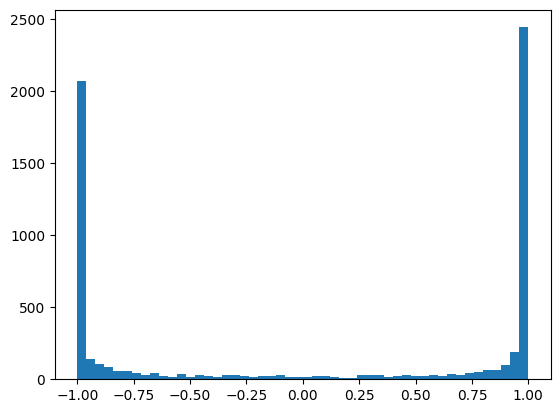

In [34]:
flattened = h.view(-1).tolist()  # Convert to 1D list
# higervalues = filter(lambda x: abs(x) > 0.99, flattened)
# result = list(higervalues) # convert filtered obj to list
# len(result) # shows how many tanh are closer to -1 and 1

# plot list of all pre-activations
#plt.hist(hpreact.view(-1).tolist(), bins=50);

# plot list of all activations - here you see most tanh output are closer to -1 and 1
plt.hist(flattened, bins=50);

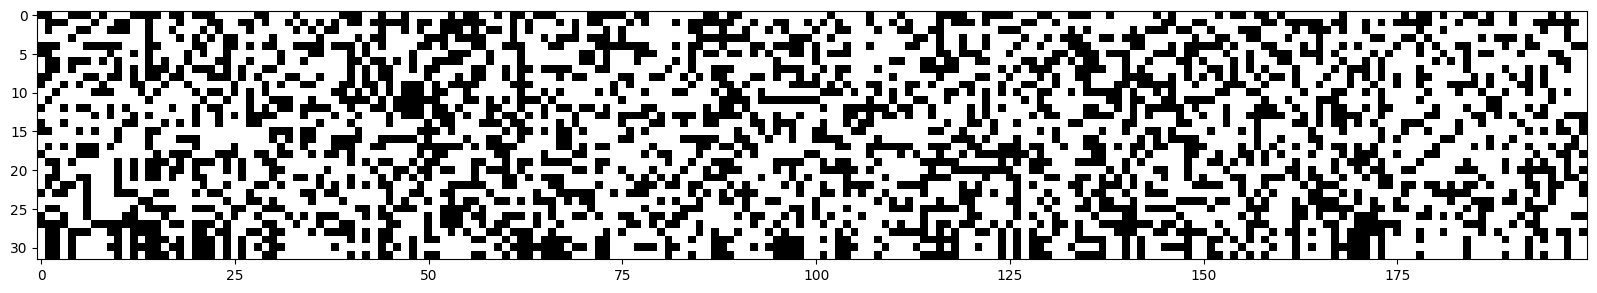

In [35]:
h.size() #[32, 200]
plt.figure(figsize=(20,10))

# we can see how each 200 neurons activation worked based on 32 inputs it received.
# here white-pixels means neuron is active for an input and balck means not-active
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest')

**Solution1: Fixing saturated tanh using "Kaiming init"(outdated optimization technique)**

We fixed the problem of saturated tanh by changing how we initially set up the weights (W1) that lead into the hidden layer where the tanh function is. We used a specific way of calculating these starting weights, like following a recipe called "Kaiming initialization". This recipe helps make sure that the numbers going into the tanh function are not too big or too small right from the start. By keeping these numbers in a good range, the tanh function is less likely to get "stuck" at its extreme values, which in turn helps the network learn better, especially in the early layers.


[Video](https://youtu.be/P6sfmUTpUmc?list=PLAqhIrjkxbuWI23v9cThsA9GvCAUhRvKZ&t=1877)

Pytorch implementation of "Kaiming init" - https://docs.pytorch.org/docs/stable/nn.init.html#torch.nn.init.kaiming_normal_

White paper: https://arxiv.org/pdf/1502.01852

In [36]:
# fix saturated tanh using "Kaiming init"
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)

### adjusting W1 and b1 for fixing saturated tanh ###
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * (5/3)/ (n_embd * block_size)**0.5 # calculation based on kaiming init so as to prevent the inputs to the tanh activation function from being too large or too small
# optionally - you can use torch.nn.init.kaiming_normal_ instead of the manual calculation "(5/3)/ (n_embd * block_size)**0.5"
# W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) # Initialize with random values
# torch.nn.init.kaiming_normal_(W1, mode='fan_in', nonlinearity='tanh') # Apply Kaiming initialization using torch.nn.init.kaiming_normal_
b1 = torch.randn(n_hidden,                        generator=g) * 0.01

# adjusting W2 and b2 for fixing the initial high loss
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.01 #here we multiply weights by 0.01. This is done to make the initial weights closer to zero, which helps in reducing the initial loss during training.
b2 = torch.randn(vocab_size,                      generator=g) * 0 #here we multiply biases by 0 to make all the biases to 0. This also contributes to making the initial logits (the raw output of the network before the softmax) closer to zero, leading to a more uniform initial probability distribution over the characters

# parameters
parameters = [C, W1, b1, W2, b2]
print('total parameters', sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

total parameters 11897


In [37]:
# Training the neuralnel
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

  break #just breaking after first loop, so that we see only the initial loss

      0/ 200000: 3.3179


**Solution2: Fixing saturated tanh using "Batch normalization"**

[Video](https://youtu.be/P6sfmUTpUmc?list=PLAqhIrjkxbuWI23v9cThsA9GvCAUhRvKZ&t=2440)


<ins>How Batch Normalization fixes saturated tanh</ins>

Similar to Kaiming init, Batch Normalization addresses the problem of saturated tanh by controlling the distribution of the inputs to the tanh activation function.(check white paper: https://arxiv.org/pdf/1502.03167)

1.  **Standardizing Inputs:** Before the input reaches the tanh function, Batch Normalization standardizes the input. During training, standardization is done based on the mean and variance of the current minibatch. The input $x$ is transformed to $\hat{x} = \frac{x - \mu_{\mathcal{B}}}{\sqrt{\sigma_{\mathcal{B}}^2 + \epsilon}}$, effectively shifting the mean to zero and scaling the variance to one.

2.  **Keeping Inputs in the Active Range:** After standardization, the inputs have a mean close to zero and a variance close to one. The tanh function has a strong gradient (is not saturated) for inputs around zero. By ensuring that the inputs to tanh are centered and scaled, Batch Normalization keeps most of the values within this non-saturated region of the tanh curve. This means that small changes in the input lead to noticeable changes in the output, and the gradient passed back during backpropagation is significant.

3.  **Learned Scale and Shift:** While the initial standardization centers and scales the inputs, Batch Normalization also includes learned parameters, $\gamma$ and $\beta$. These parameters allow the network to learn the optimal mean and variance for the inputs to the tanh layer. Even with these learned parameters, the values are generally kept within a range that avoids extreme saturation, as the network learns to adjust $\gamma$ and $\beta$ to minimize the overall loss, which benefits from having non-zero gradients.

*Detailed working:*

Suppose you have a dataset of 10,000 items and you're processing them in batches of 1,000.

During one training epoch, your dataset of 10,000 items will be divided into 10 batches (10,000 / 1,000 = 10).

Now, let's focus on what happens when the neural network processes one of these batches (a mini-batch of 1,000 items) and it reaches a layer where Batch Normalization is applied.

1. Data passes through the layer before Batch Norm: The 1,000 items in the current batch pass through the linear transformation (or other operation) of the layer just before the Batch Normalization step. This produces a set of outputs for these 1,000 items. Let's say this layer has 200 neurons (like your hidden layer). For this batch, you'll have 1,000 sets of 200 output values.

2. Calculate Mean and Variance for the Batch: Batch Normalization now looks at these 1,000 sets of 200 output values. For each of the 200 neurons, it calculates the mean and variance across the 1,000 items in the current batch. So, it calculates 200 means (one for each neuron) and 200 variances (one for each neuron).

3. Normalize the Batch: Using the calculated batch mean and variance for each neuron, Batch Normalization normalizes the output of that neuron for every item in the batch. The formula for normalization is:

Normalized Value = (Original Value - Batch Mean) / sqrt(Batch Variance + epsilon)

(The epsilon is a small number added for numerical stability to prevent division by zero).

This step ensures that for this specific batch, the outputs of each neuron now have a mean of approximately 0 and a variance of approximately 1.

4. Scale and Shift (Learnable Parameters): After normalizing, Batch Normalization applies two learnable parameters per neuron: a scaling factor (gamma, γ) and a shifting factor (beta, β).

Scaled and Shifted Value = Gamma * Normalized Value + Beta

These parameters allow the network to learn if it needs to scale or shift the normalized values to be in a different distribution than mean 0 and variance 1, if that helps with learning. Initially, gamma is usually initialized to 1 and beta to 0, so the output is just the normalized value.

5. Output of Batch Norm: The scaled and shifted values are the outputs of the Batch Normalization layer for this batch. These outputs then pass to the next layer (e.g., the tanh activation function in your case).

**Can batch normaliztion be applied to all hidden layers?**

Batch Normalization can be applied to any or all of the hidden layers in a neural network.

It's a common practice to add Batch Normalization layers after the linear transformations and before the activation functions in multiple hidden layers. Doing so helps to stabilize the inputs to the activation functions throughout the network, not just in the first hidden layer.

This can lead to more stable training, allow for higher learning rates, and often results in faster convergence and better performance

**Additional Benefits of Batch Normalization**

Beyond helping to prevent saturated activation functions like tanh and improving the stability of training by reducing internal covariate shift, Batch Normalization offers several other significant advantages:

1.  **Enabling Higher Learning Rates:** Batch Normalization makes the training process more stable. Because the distribution of inputs to each layer is normalized and kept within a reasonable range, the gradients are less likely to become too large or too small. This stability allows practitioners to use higher learning rates than would typically be possible without Batch Normalization. Higher learning rates can lead to faster convergence of the model during training.

2.  **Reducing the Need for Strong Regularization:** Batch Normalization has a slight regularization effect. By normalizing based on minibatch statistics, it introduces a small amount of noise into the training process, as the mean and variance are calculated on different subsets of the data in each iteration. This noise can help prevent the model from overfitting to the training data, similar to how techniques like dropout work. Consequently, using Batch Normalization often reduces the need for other strong regularization techniques or allows for weaker forms of regularization to be used.

3.  **Making the Network Less Sensitive to Initial Weights:** While good initialization techniques like Kaiming initialization are still beneficial, Batch Normalization makes the network's performance less dependent on the precise values of the initial weights. Because Batch Normalization continuously normalizes the activations, it can often compensate for suboptimal initializations, leading to more reliable training across different initial conditions.

4.  **Potentially Improving Generalization:** By helping to prevent overfitting (through its regularization effect) and making the training process more stable, Batch Normalization can contribute to better generalization performance on unseen data (the test set). A model that generalizes well is able to make accurate predictions on data it hasn't seen during training, which is the ultimate goal of machine learning.

In [42]:
# fix saturated tanh using "Batch normalization"
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g)
## skipping bias - because the bnbias parameter in Batch Normalization will serve a similar purpose of shifting the normalized values
#b1 = torch.randn(n_hidden,                        generator=g)

# adjusting W2 and b2 for fixing the initial high loss
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.01 #here we multiply weights by 0.01. This is done to make the initial weights closer to zero, which helps in reducing the initial loss during training.
b2 = torch.randn(vocab_size,                      generator=g) * 0 #here we multiply biases by 0 to make all the biases to 0. This also contributes to making the initial logits (the raw output of the network before the softmax) closer to zero, leading to a more uniform initial probability distribution over the characters

### BatchNorm parameters ##
bngain = torch.ones((1, n_hidden)) # Initializes the learnable scaling parameter (gamma, γ) for Batch Normalization to ones. This means initially, the normalized values won't be scaled.
bnbias = torch.zeros((1, n_hidden)) # Initializes the learnable shifting parameter (beta, β) for Batch Normalization to zeros. This means initially, the normalized values won't be shifted
# following two are to calculate the accumulated mean and standard deviation from intermediate bnmean and bnstd.
# these two values will be later used for inference,test etc
bnmean_running = torch.zeros((1, n_hidden)) # initially it should be roughly 0, so torch.zeros
bnstd_running = torch.ones((1, n_hidden)) # initially it should be roughly 1, so torch.ones

# parameters
#parameters = [C, W1, b1, W2, b2, bngain, bnbias]
parameters = [C, W1, W2, b2, bngain, bnbias]
print('total parameters', sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

total parameters 12097


In [43]:
# Training the neuralnel
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  ## here we are not including bias(b1) because in batch-normalization we have 'bnbias' which does that same
  hpreact = embcat @ W1 #+ b1
  ### BatchNorm ##
  bnmeani = hpreact.mean(0, keepdim=True) # Calculates the mean of the pre-activation values across the batch for each neuron in the hidden layer
  bnstdi = hpreact.std(0, keepdim=True) # Calculates the standard deviation of the pre-activation values across the batch for each neuron
  # This is the core Batch Normalization step. It standardizes hpreact using the batch mean (bnmeani) and standard deviation (bnstdi), and then scales and shifts the result using the learned parameters bngain and bnbias
  hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias
  with torch.no_grad(): # this will tell pytorch not to build grad for the following two tensors.
    bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani #Updates the running mean. This is an exponential moving average, where the new running mean is a combination of the old running mean (99.9%) and the current batch mean (0.1%).
    bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi #Updates the running standard deviation in the same way
  ### BatchNorm-ends ##
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

      0/ 200000: 3.3239
  10000/ 200000: 2.0845
  20000/ 200000: 2.7028
  30000/ 200000: 2.0979
  40000/ 200000: 2.2475
  50000/ 200000: 1.9333
  60000/ 200000: 2.1116
  70000/ 200000: 2.3807
  80000/ 200000: 2.5232
  90000/ 200000: 2.1671
 100000/ 200000: 2.3136
 110000/ 200000: 2.4021
 120000/ 200000: 1.6231
 130000/ 200000: 2.0025
 140000/ 200000: 2.3425
 150000/ 200000: 2.0754
 160000/ 200000: 2.0543
 170000/ 200000: 2.4216
 180000/ 200000: 2.1328
 190000/ 200000: 2.1848


In [44]:
# checking the train and val/dev loss
@torch.no_grad() # this decorator disables gradient tracking of pytorch
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  hpreact = embcat @ W1 + b1
  ### BatchNorm ##
  # bnmeani = hpreact.mean(0, keepdim=True) # mean of a batch
  # bnstdi = hpreact.std(0, keepdim=True) # standard deivation

  # using the bnmean_running and bnstd_running values that we got after training
  hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
  ### BatchNorm-ends ##
  h = torch.tanh(hpreact) # (N, n_hidden)
  logits = h @ W2 + b2 # (N, vocab_size)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.1126620769500732
val 2.1382226943969727


Pytorch-ifying the code
--------